# Regularización y validación temporal

105 trabajos completados; 228 ajustes neuronales incluyendo selección interna y reentrenamiento; 114 checkpoints finales comprobados. Tiempo acumulado de trabajos: 18.8 minutos. Dos procesos CPU, un hilo por proceso. Los trabajos por horizonte tienen tres ramas.

Para el bloque fijo, la época se elige con ajuste anterior a 2016 y selección interna 2016–2017. Después se inicializa otra red y se ajusta todo el histórico anterior a 2018 durante esas épocas. La validación 2018–2022 solo se evalúa con los pesos ya fijados. Sigue interviniendo al comparar configuraciones, por lo que no es un test independiente. El test 2023–2024 permanece reservado.

Criterio fijado: media de ratios RMSE/spot por año objetivo elegible, después por horizonte, semilla y arquitectura. Diferencias menores de 0,005 favorecen menos ramas y parámetros. La condición elegida comparte entradas, ventana y configuración entre las tres celdas. Las métricas de la tabla son medias de métricas individuales; las figuras usan el promedio real de predicciones.

[Vista HTML](../experiments/regularization_20261118/report/comparacion.html). Este notebook lee resultados guardados; no entrena.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'experiments/regularization_20261118/report/candidate.json').is_file())
REPORT = ROOT / 'experiments/regularization_20261118/report'
display(pd.read_csv(REPORT / 'selected_validation_means.csv'))

,architecture,horizon,n,mae,mse,rmse,r2,rmse_std,relative_rmse,relative_rmse_vs_future,year_balanced_ratio
0,GRU,5,1263,3.999405,32.655549,5.714475,0.927045,0.021990,1.002082,1.189379,0.992639
1,GRU,63,1205,10.859786,240.497534,15.505430,0.486567,0.344589,0.969883,1.045529,0.871063
2,GRU,252,1020,19.070524,558.263511,23.437501,-0.027753,3.663411,0.849881,0.870204,0.860266
3,LSTM,5,1263,4.075490,33.402824,5.778469,0.925376,0.134800,1.013304,1.202698,1.011204
4,LSTM,63,1205,11.464692,255.363843,15.980026,0.454829,0.062432,0.999569,1.077531,0.951257
5,LSTM,252,1020,22.056080,707.119135,26.552046,-0.301793,1.778206,0.962819,0.985843,0.948453
6,RNN,5,1263,3.982938,33.204056,5.762205,0.925820,0.039704,1.010451,1.199313,0.994359
7,RNN,63,1205,10.273602,234.724747,15.317907,0.498891,0.360154,0.958153,1.032885,0.806105
8,RNN,252,1020,16.934178,434.300264,20.822755,0.200461,1.034263,0.755066,0.773122,0.787216


## Curvas reales y predichas: candidato y control

Cada punto se dibuja en la fecha objetivo. Las figuras de precio muestran la media de tres semillas.

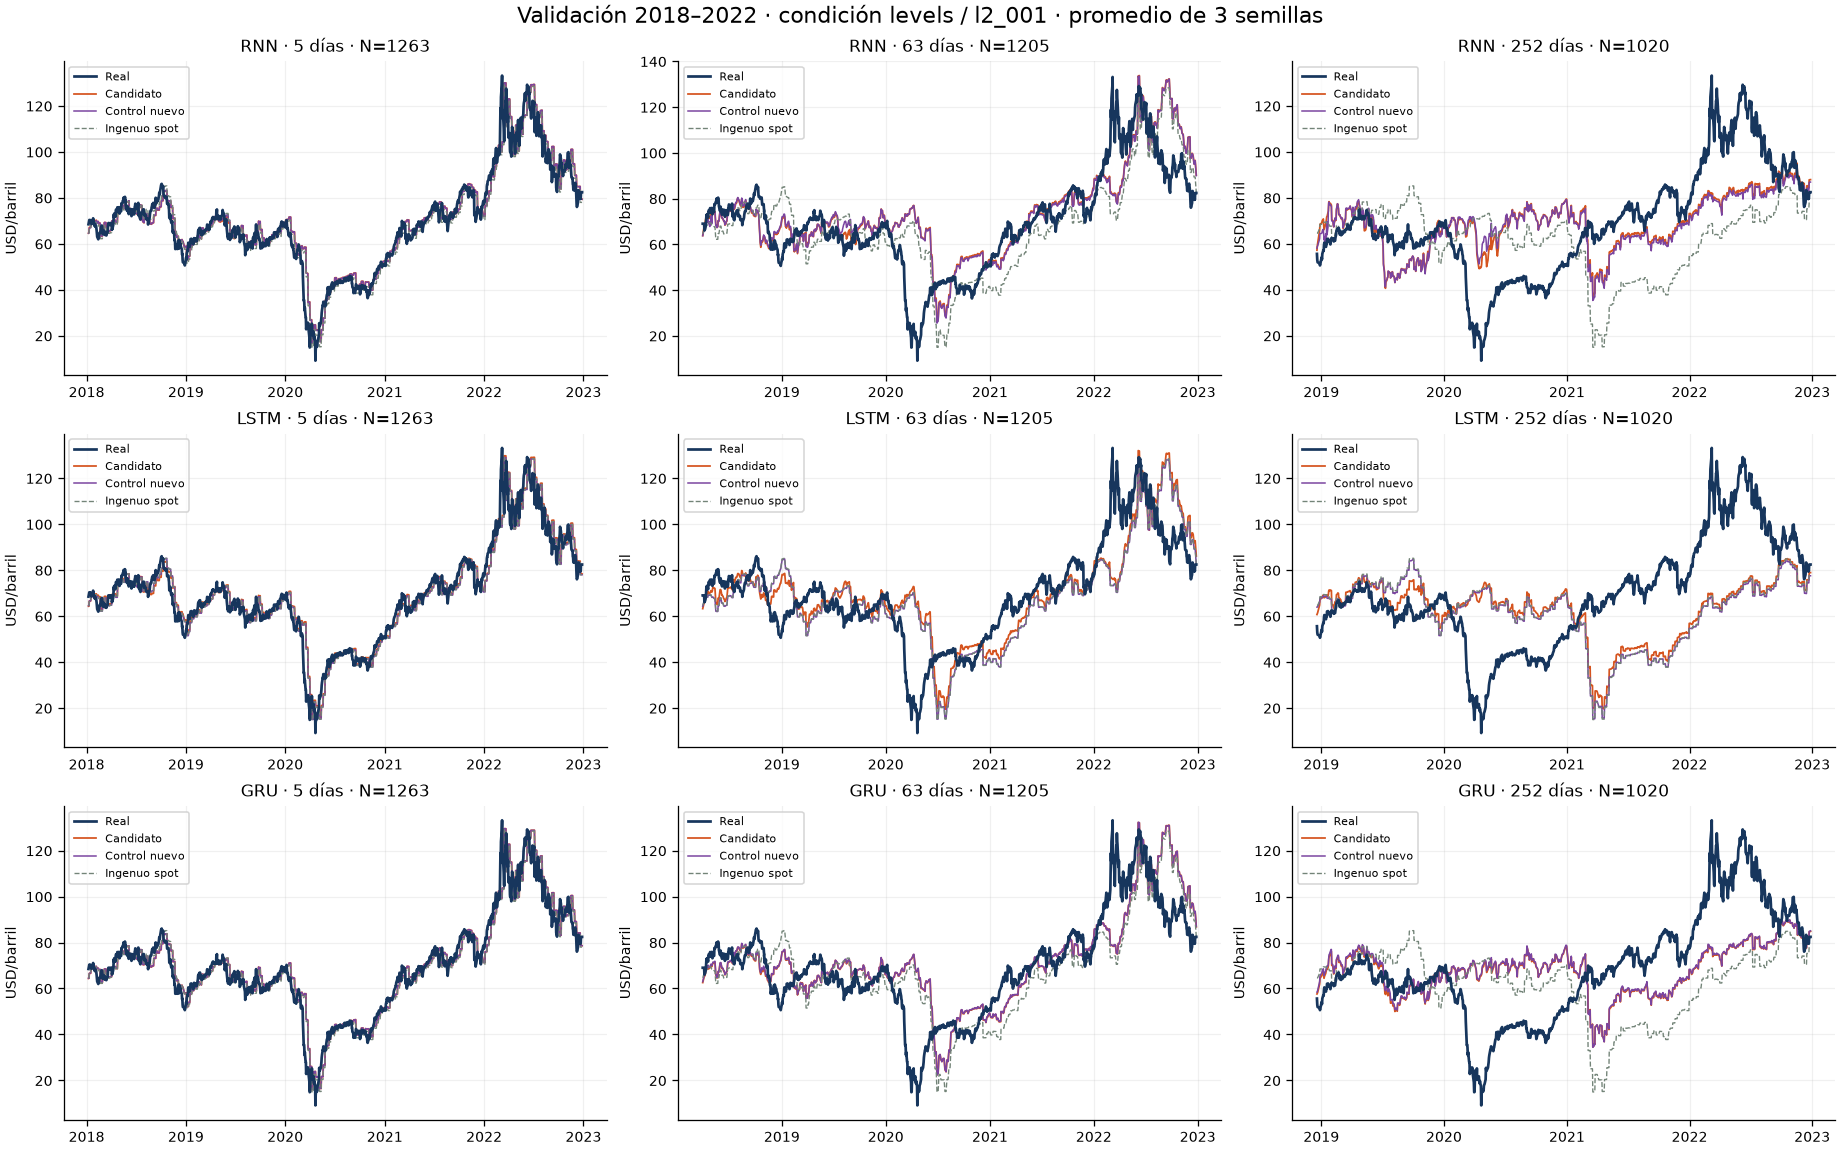

In [2]:
display(Image(filename=str(REPORT / '01_comparacion.png')))

## Curvas para detectar sobreajuste durante la selección interna

Señal interna de deterioro superior al 2% mientras baja la pérdida de ajuste: 9/9 ramas del candidato y 8/9 del control. Es un diagnóstico heurístico de la selección interna; no demuestra ausencia de sobreajuste ni mide por sí solo la calidad del modelo reentrenado. Las curvas corresponden a la selección, no a evaluar 2018–2022 en cada época. La línea vertical minimiza el ratio RMSE/spot interno, que puede elegir una época distinta del mínimo del MSE normalizado dibujado; son agregaciones diferentes.

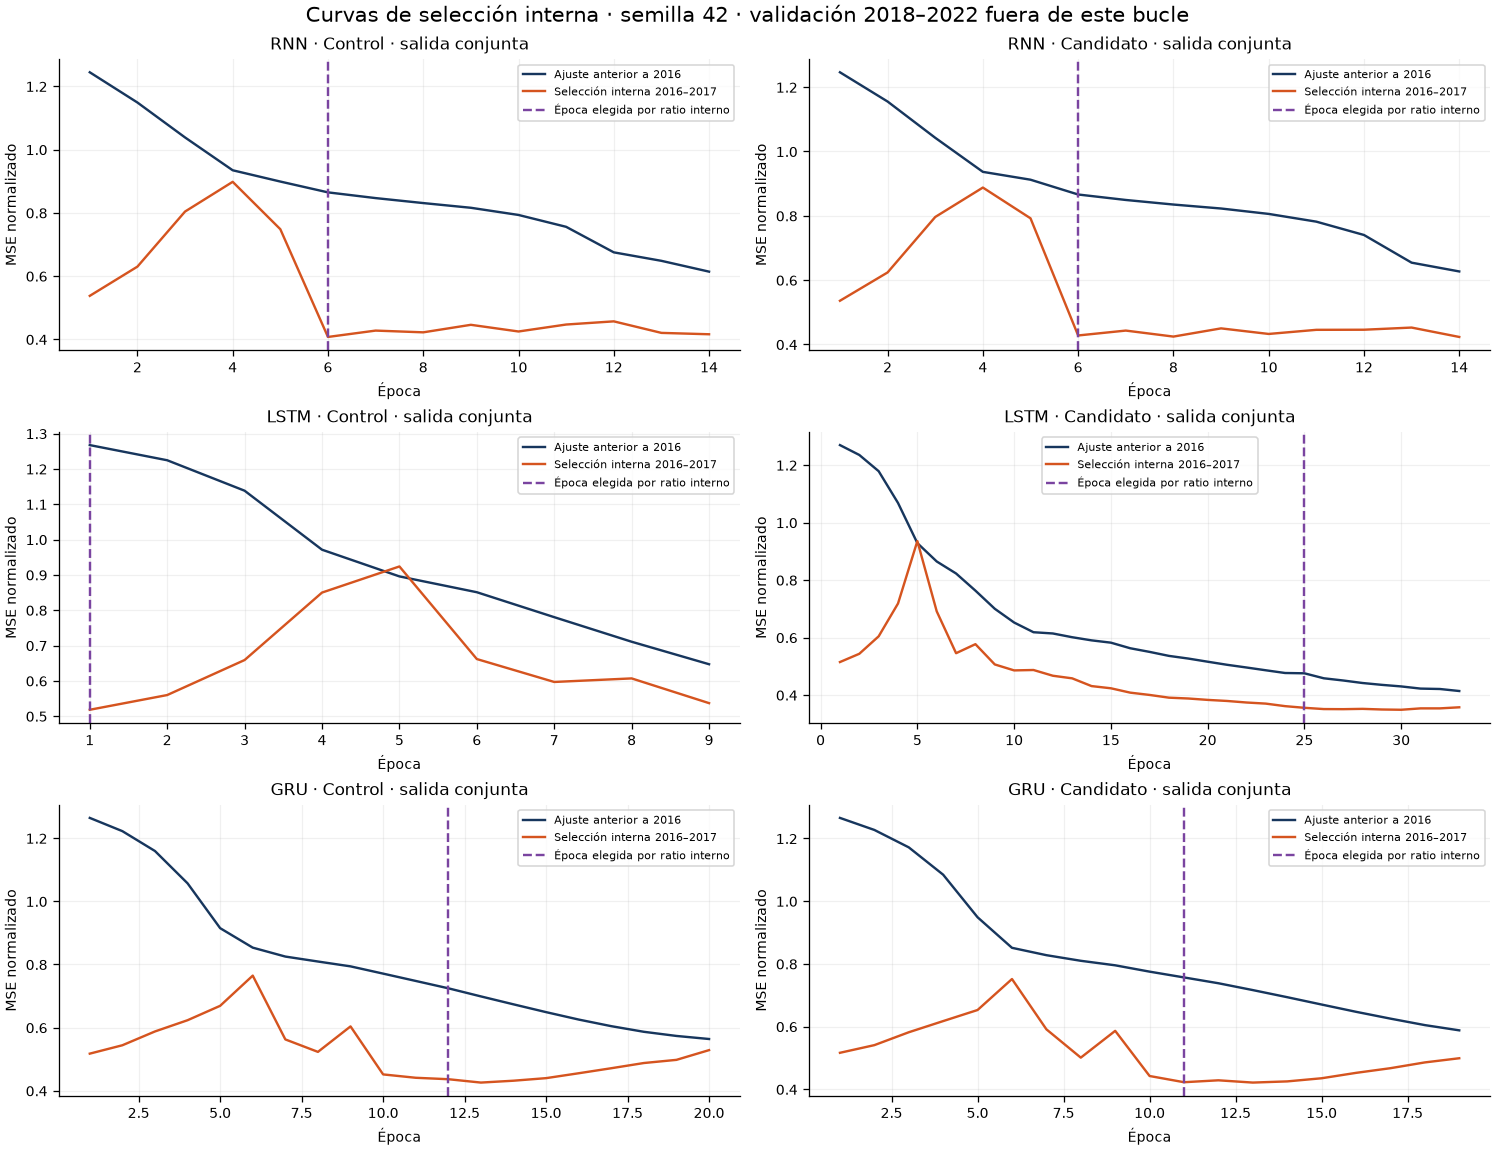

In [3]:
display(Image(filename=str(REPORT / '02_curvas_internas.png')))

## Detalle del candidato frente a precios reales y futuros conocidos

Cada punto se dibuja en la fecha objetivo. Las figuras de precio muestran la media de tres semillas.

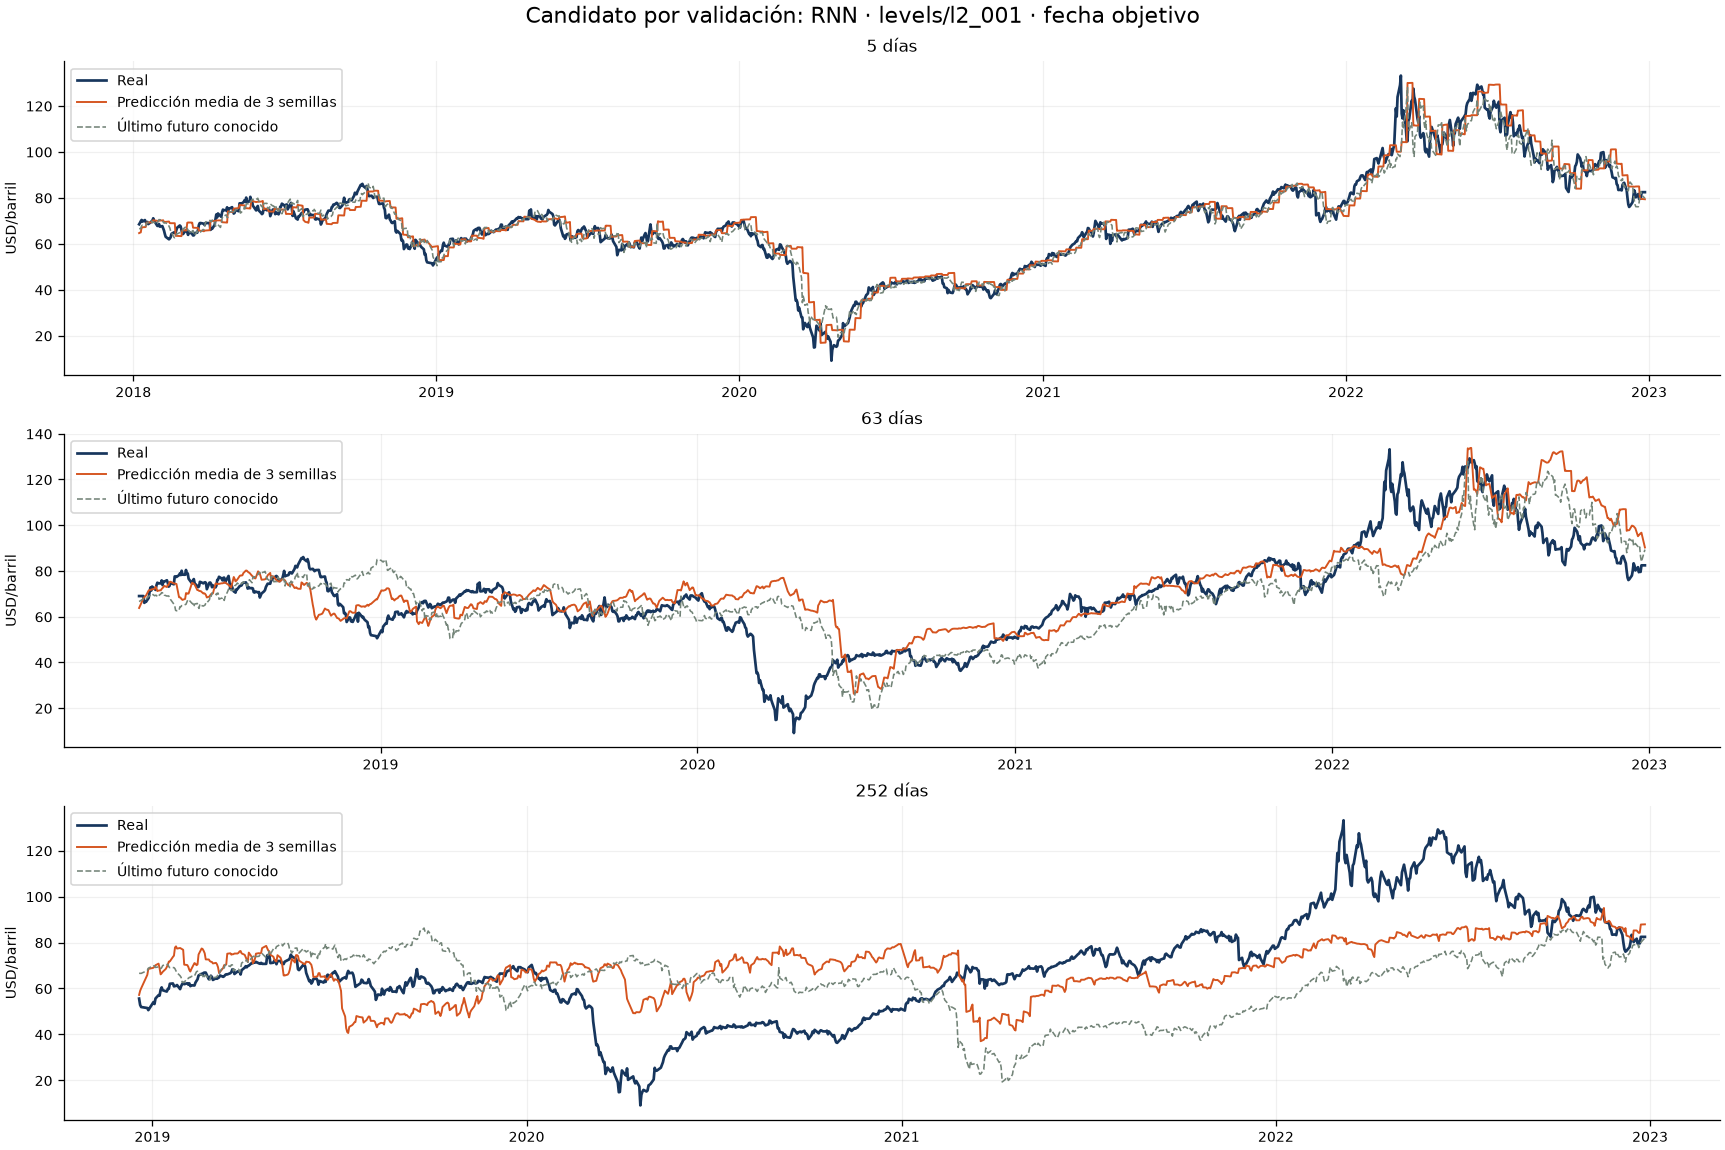

In [4]:
display(Image(filename=str(REPORT / '03_detalle.png')))

## Límites y pendientes

El panel estricto mantiene la cobertura de 2012 en adelante; esta campaña no inventa fechas de publicación anteriores a la cobertura de ALFRED ni rellena precios objetivo. No se amplía aquí hasta 2000. Los cortes walk-forward son una comprobación retrospectiva de desarrollo sobre años ya usados para comparar candidatos, no otra muestra independiente. La predicción de 252 días tiene ventanas fuertemente solapadas. Los intervalos de predicción continúan pendientes de calibración.